In [20]:
!pip install pandas numpy scikit-learn matplotlib seaborn nltk

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [22]:
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package punkt to /Users/wangying/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/wangying/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/wangying/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/wangying/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /Users/wangying/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [23]:
data = {
    'review': [
        "This product is amazing and works perfectly.",
        "I absolutely love this product.",
        "Excellent quality and great customer service.",
        "The product is terrible and completely useless.",
        "Very disappointed with the quality.",
        "I hate this product. It is a waste of money.",
        "The experience was wonderful and enjoyable.",
        "The service was awful and very frustrating.",
        "Great product. I would definitely recommend it.",
        "Poor quality. I would never buy this again."
    ],
    'sentiment': [
        1, 1, 1, 0, 0, 0, 1, 0, 1, 0
    ]
}

df = pd.DataFrame(data)

print(df.head())

                                            review  sentiment
0     This product is amazing and works perfectly.          1
1                  I absolutely love this product.          1
2    Excellent quality and great customer service.          1
3  The product is terrible and completely useless.          0
4              Very disappointed with the quality.          0


In [24]:
print(df.head())
print(df.shape)
print(df.info())

                                            review  sentiment
0     This product is amazing and works perfectly.          1
1                  I absolutely love this product.          1
2    Excellent quality and great customer service.          1
3  The product is terrible and completely useless.          0
4              Very disappointed with the quality.          0
(10, 2)
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     10 non-null     str  
 1   sentiment  10 non-null     int64
dtypes: int64(1), str(1)
memory usage: 292.0 bytes
None


In [8]:
print(df.shape)

print(df['sentiment'].value_counts())

print(df['sentiment'].value_counts(normalize=True))

(10, 2)
sentiment
1    5
0    5
Name: count, dtype: int64
sentiment
1    0.5
0    0.5
Name: proportion, dtype: float64


Step 3 — Data exploration and visualization
Before training a model, examine the dataset.
3.1 Check for missing values

In [9]:
print(df.isnull().sum())

review       0
sentiment    0
dtype: int64


In [10]:
df = df.dropna(subset=['review', 'sentiment'])

In [11]:
print("Duplicate reviews:", df['review'].duplicated().sum())

Duplicate reviews: 0


In [25]:
df = df.drop_duplicates(subset=['review'])

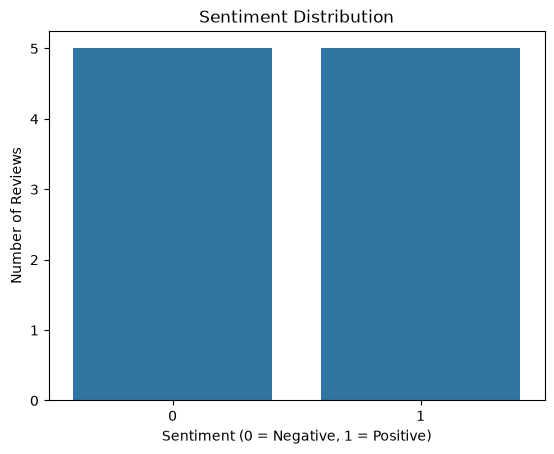

In [26]:
sns.countplot(data=df, x='sentiment')

plt.title('Sentiment Distribution')
plt.xlabel('Sentiment (0 = Negative, 1 = Positive)')
plt.ylabel('Number of Reviews')

plt.show()

In [27]:
stop_words = set(stopwords.words('english'))

# Preserve negation words for sentiment analysis
negation_words = {'not', 'no', 'nor', 'never'}

stop_words = stop_words - negation_words

lemmatizer = WordNetLemmatizer()

In [28]:
def preprocess_text(text):

    # Lowercase
    text = text.lower()

    # Remove punctuation
    text = re.sub(r'[^\w\s]', '', text)

    # Tokenization
    tokens = word_tokenize(text)

    # Stop-word removal
    tokens = [
        token for token in tokens
        if token not in stop_words
    ]

    # Lemmatization
    tokens = [
        lemmatizer.lemmatize(token)
        for token in tokens
    ]

    # Convert tokens back into text
    processed_text = ' '.join(tokens)

    return processed_text

In [29]:
df['cleaned_review'] = df['review'].apply(preprocess_text)

In [30]:
display(df[['review', 'cleaned_review']].head(10))

,review,cleaned_review
0,This product is amazing and works perfectly.,product amazing work perfectly
1,I absolutely love this product.,absolutely love product
2,Excellent quality and great customer service.,excellent quality great customer service
3,The product is terrible and completely useless.,product terrible completely useless
4,Very disappointed with the quality.,disappointed quality
5,I hate this product. It is a waste of money.,hate product waste money
6,The experience was wonderful and enjoyable.,experience wonderful enjoyable
7,The service was awful and very frustrating.,service awful frustrating
8,Great product. I would definitely recommend it.,great product would definitely recommend
9,Poor quality. I would never buy this again.,poor quality would never buy


In [31]:
X = df['cleaned_review']
y = df['sentiment']

In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [33]:
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 8
Testing samples: 2


In [34]:
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 1),
    min_df=1,
    max_df=1.0
)

In [35]:
X_train_tfidf = tfidf.fit_transform(X_train)

In [36]:
X_test_tfidf = tfidf.transform(X_test)

In [37]:
print("Training matrix:", X_train_tfidf.shape)
print("Testing matrix:", X_test_tfidf.shape)

print("Vocabulary size:", len(tfidf.vocabulary_))

Training matrix: (8, 25)
Testing matrix: (2, 25)
Vocabulary size: 25


In [38]:
feature_names = tfidf.get_feature_names_out()

print(feature_names[:50])

['absolutely' 'amazing' 'buy' 'completely' 'customer' 'disappointed'
 'enjoyable' 'excellent' 'experience' 'great' 'hate' 'love' 'money'
 'never' 'perfectly' 'poor' 'product' 'quality' 'service' 'terrible'
 'useless' 'waste' 'wonderful' 'work' 'would']


In [39]:
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [40]:
model.fit(X_train_tfidf, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [41]:
y_pred = model.predict(X_test_tfidf)

In [42]:
y_prob = model.predict_proba(X_test_tfidf)

In [43]:
prediction_results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred,
    'Negative Probability': y_prob[:, 0],
    'Positive Probability': y_prob[:, 1]
})

display(prediction_results)

,Actual,Predicted,Negative Probability,Positive Probability
0,0,1,0.446297,0.553703
1,1,1,0.491694,0.508306


In [44]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.5


In [45]:
precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

print("Precision:", precision)

Precision: 0.5


In [46]:
recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

print("Recall:", recall)

Recall: 1.0


In [47]:
f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

print("F1-score:", f1)

F1-score: 0.6666666666666666


In [48]:
results = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score'],
    'Score': [accuracy, precision, recall, f1]
})

display(results)

,Metric,Score
0,Accuracy,0.500000
1,Precision,0.500000
2,Recall,1.000000
3,F1-score,0.666667


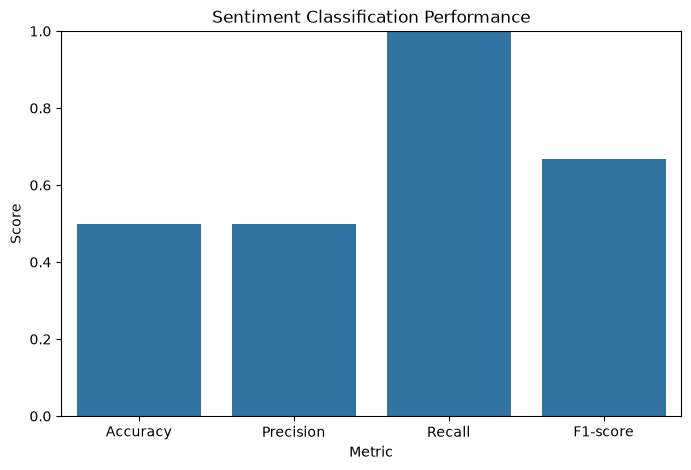

In [49]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=results,
    x='Metric',
    y='Score'
)

plt.title('Sentiment Classification Performance')
plt.ylim(0, 1)

plt.show()

In [50]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[0 1]
 [0 1]]


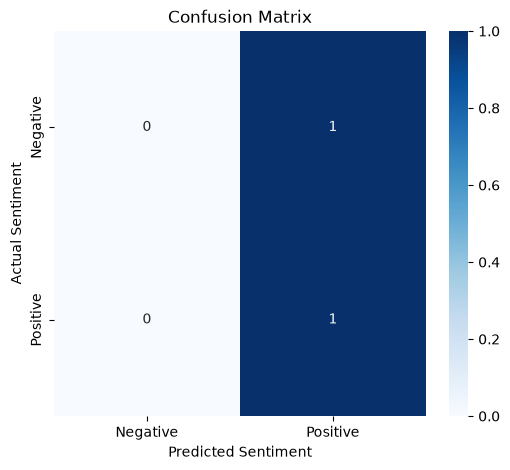

In [51]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)

plt.title('Confusion Matrix')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')

plt.show()

In [52]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=['Negative', 'Positive'],
        zero_division=0
    )
)

              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00         1
    Positive       0.50      1.00      0.67         1

    accuracy                           0.50         2
   macro avg       0.25      0.50      0.33         2
weighted avg       0.25      0.50      0.33         2



In [53]:
feature_names = tfidf.get_feature_names_out()

coefficients = model.coef_[0]

feature_importance = pd.DataFrame({
    'word': feature_names,
    'coefficient': coefficients
})

In [54]:
positive_features = feature_importance.sort_values(
    by='coefficient',
    ascending=False
)

display(positive_features.head(20))

,word,coefficient
0,absolutely,0.264253
11,love,0.264253
22,wonderful,0.229844
6,enjoyable,0.229844
8,experience,0.229844
14,perfectly,0.220042
23,work,0.220042
1,amazing,0.220042
4,customer,0.198838
18,service,0.198838


In [55]:
negative_features = feature_importance.sort_values(
    by='coefficient',
    ascending=True
)

display(negative_features.head(20))

,word,coefficient
5,disappointed,-0.328099
17,quality,-0.228777
12,money,-0.225116
21,waste,-0.225116
20,useless,-0.225116
3,completely,-0.225116
19,terrible,-0.225116
10,hate,-0.225116
15,poor,-0.187081
13,never,-0.187081


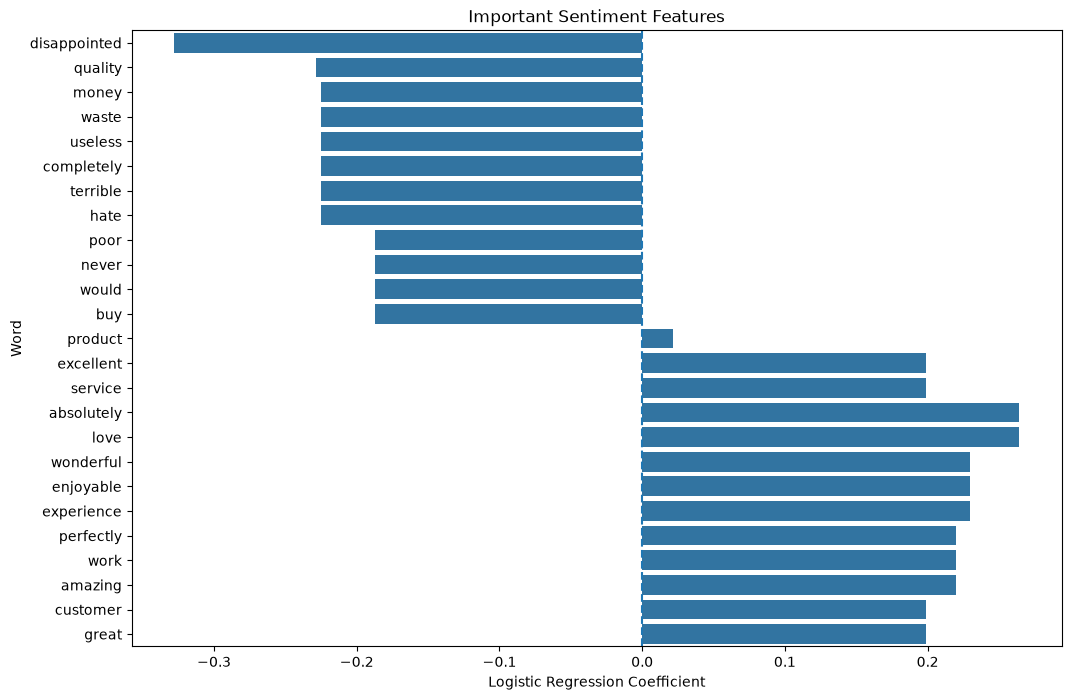

In [56]:
top_positive = positive_features.head(15)

top_negative = negative_features.head(15)

top_features = pd.concat([
    top_negative,
    top_positive
])

plt.figure(figsize=(12, 8))

sns.barplot(
    data=top_features,
    x='coefficient',
    y='word'
)

plt.title('Important Sentiment Features')
plt.xlabel('Logistic Regression Coefficient')
plt.ylabel('Word')

plt.axvline(x=0, linestyle='--')

plt.show()

In [57]:
def predict_sentiment(review):

    cleaned_review = preprocess_text(review)

    review_vector = tfidf.transform([cleaned_review])

    prediction = model.predict(review_vector)[0]

    probabilities = model.predict_proba(review_vector)[0]

    sentiment = 'Positive' if prediction == 1 else 'Negative'

    return {
        'review': review,
        'sentiment': sentiment,
        'negative_probability': probabilities[0],
        'positive_probability': probabilities[1]
    }

In [58]:
test_reviews = [
    "This product is fantastic. I love it!",
    "Terrible quality and very disappointing.",
    "The product works fine, but the service was awful.",
    "I would definitely recommend this to everyone.",
    "Not worth the money. I regret buying it."
]

for review in test_reviews:

    result = predict_sentiment(review)

    print(result)
    print('-' * 60)

{'review': 'This product is fantastic. I love it!', 'sentiment': 'Positive', 'negative_probability': np.float64(0.4374437487643358), 'positive_probability': np.float64(0.5625562512356642)}
------------------------------------------------------------
{'review': 'Terrible quality and very disappointing.', 'sentiment': 'Negative', 'negative_probability': np.float64(0.5743622069534784), 'positive_probability': np.float64(0.4256377930465216)}
------------------------------------------------------------
{'review': 'The product works fine, but the service was awful.', 'sentiment': 'Positive', 'negative_probability': np.float64(0.42655700636202465), 'positive_probability': np.float64(0.5734429936379754)}
------------------------------------------------------------
{'review': 'I would definitely recommend this to everyone.', 'sentiment': 'Negative', 'negative_probability': np.float64(0.5424661690519313), 'positive_probability': np.float64(0.45753383094806865)}
----------------------------------

In [59]:
tfidf_bigram = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

In [60]:
X_train_bigram = tfidf_bigram.fit_transform(X_train)

X_test_bigram = tfidf_bigram.transform(X_test)

In [61]:
model_bigram = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model_bigram.fit(X_train_bigram, y_train)

y_pred_bigram = model_bigram.predict(X_test_bigram)

In [62]:
print("Accuracy:", accuracy_score(y_test, y_pred_bigram))

print("Precision:", precision_score(
    y_test, y_pred_bigram, zero_division=0
))

print("Recall:", recall_score(
    y_test, y_pred_bigram, zero_division=0
))

print("F1-score:", f1_score(
    y_test, y_pred_bigram, zero_division=0
))

Accuracy: 0.5
Precision: 0.5
Recall: 1.0
F1-score: 0.6666666666666666


In [63]:
max_features_values = [500, 1000, 3000, 5000, 10000]

In [64]:
min_df_values = [1, 2, 3, 5]

In [65]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline

pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=5000,
        ngram_range=(1, 2)
    )),
    ('classifier', LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

cv_scores = cross_val_score(
    pipeline,
    X,
    y,
    cv=5,
    scoring='f1'
)

print("F1 scores:", cv_scores)

print("Mean F1:", cv_scores.mean())

print("Standard deviation:", cv_scores.std())

F1 scores: [0.66666667 0.         0.         0.         1.        ]
Mean F1: 0.3333333333333333
Standard deviation: 0.4216370213557839
